# **Criatura Lendária: Tiamat**

#### Aprendizado de Máquina: 2º Semestre 2026 - **Prof. Daniel R. Cassar** | Ilum Escola de Ciência (CNPEM)
##### **Angelica Aracava Lopes (2610047) - Turma 2026**
---

## **1. Introdução e Objetivo**

Nanopartículas de óxidos metálicos (ZnO, TiO₂, Fe₃O₄ etc.) são muito usadas em biomedicina, cosméticos e catálise, mas podem ser **citotóxicas** (tóxicas para células). Testar toda combinação de material, tamanho, dose e tipo celular em laboratório é caro; um modelo de aprendizado de máquina que **classifique um experimento como tóxico ou não tóxico** a partir de propriedades físico-químicas e das condições do ensaio pode ajudar a priorizar experimentos.

**Objetivo:** comparar um baseline e cinco algoritmos/pipelines (Random Forest, XGBoost, SVM, regressão logística com pipeline otimizado e kNN), cada um com 100 conjuntos de hiperparâmetros testados pelo Optuna, em um problema de **classificação binária** (`Toxicity`).

**Dados:** conjunto *HaHa-Manual*, com dados de toxicidade extraídos manualmente da literatura (Ha e Ha, 2025, ver Referências), licença CC-BY-4.0. São dados experimentais reais, não sintéticos.

**Ponto de atenção principal:** o mesmo material aparece em várias linhas (variando dose, tempo de exposição e célula). Um split aleatório colocaria linhas "irmãs" no treino e no teste, inflando o desempenho. Por isso, todo o trabalho usa **divisão por grupos de material**.

## **2. Configuração e Carregamento dos dados**

Começamos **importando as bibliotecas** e fixando uma **semente aleatória para reprodutibilidade**. O número de tentativas do Optuna (`N_TRIALS`) fica em uma variável única: 100 por algoritmo, como exigido no projeto.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score, roc_auc_score, RocCurveDisplay)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

SEED = 7
N_TRIALS = int(os.environ.get("N_TRIALS", 100))   # 100 tentativas por algoritmo

# ---------------------------------------------------------------------------
# PALETA E ESTILO DOS GRÁFICOS: 
# ---------------------------------------------------------------------------
COR_PRIMARIA   = "rebeccapurple"   # histogramas e barras simples
COR_TOXICO     = "mediumvioletred"   # classe tóxica
COR_NAO_TOXICO = "seagreen"   # classe não tóxica
COR_DESTAQUE   = "darkorange"   # linhas de referência
COR_NEUTRA     = "dimgray"   # barras sem efeito e linha de acaso

CMAP_CORR      = "RdPu"    # mapa de calor das correlações
CMAP_METRICAS  = "BuPu"    # tabela de métricas no teste
CMAP_CONFUSAO  = "Purples"     # matriz de confusão

CORES_MODELOS = {            # uma cor fixa por modelo, usada em todos os gráficos
    "Dummy (classe majoritária)":   "dimgray",
    "Regressão Logística (padrão)": "darkorange",
    "Random Forest":                "seagreen",
    "XGBoost":                      "mediumvioletred",
    "SVM (RBF)":                    "darkslateblue",
    "Regressão Logística (otimizada)": "sienna",
    "kNN":                          "slateblue"}

COR_GRUPO      = "rebeccapurple"   # divisão por grupos de material (seção 9.1)
COR_ALEATORIO  = "darkorange"   # divisão aleatória por linhas (seção 9.1)

plt.rcParams.update({"axes.grid": False, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

Agora carregamos o CSV. **Se o arquivo não estiver na mesma pasta de execução do notebook, o código baixa direto do Zenodo** (fonte original, citada nas Referências).

In [2]:
ARQUIVO_DADOS = "HaHa-Manual.csv"
DADOS_URL = "https://zenodo.org/records/15385143/files/HaHa-Manual.csv?download=1"

if os.path.exists(ARQUIVO_DADOS):
	df = pd.read_csv(ARQUIVO_DADOS)
else:
	df = pd.read_csv(DADOS_URL)
	df.to_csv(ARQUIVO_DADOS, index=False) #salva o arquivo na pasta de execução

print(df.shape)
df.head()

(3440, 17)


,Material_type,Core_size,Hydro_size,Surface_charge,Surface_area,Formation_enthalpy,Conduction_band,Valence_band,Electronegativity,Assay,Cell_name,Cell_species,Cell_origin,Cell_type,Exposure_time,Exposure_dose,Toxicity
0,Mn3O4,347.0,338.0,-16.4,14.0,-8.91,-4.65,-7.63,5.92,MTT,A549,Human,Lung,Cancer,24.0,0.0,Non-Toxic
1,Mn3O4,347.0,338.0,-16.4,14.0,-8.91,-4.65,-7.63,5.92,MTT,A549,Human,Lung,Cancer,24.0,1.0,Non-Toxic
2,Mn3O4,347.0,338.0,-16.4,14.0,-8.91,-4.65,-7.63,5.92,MTT,A549,Human,Lung,Cancer,24.0,5.0,Non-Toxic
3,Mn3O4,347.0,338.0,-16.4,14.0,-8.91,-4.65,-7.63,5.92,MTT,A549,Human,Lung,Cancer,24.0,10.0,Non-Toxic
4,Mn3O4,364.0,338.0,-23.0,39.0,-8.91,-4.65,-7.63,5.92,MTT,A549,Human,Lung,Cancer,24.0,0.0,Non-Toxic


## **3. Análise exploratória**

Antes de modelar **é preciso entender os dados**: tipos das colunas, valores ausentes, balanceamento do alvo, distribuição dos atributos e relações entre eles. **Cada linha do conjunto de dados é um experimento** (material + célula + condições de exposição).

In [3]:
print(df.dtypes)
print("\nValores ausentes por coluna (%):")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))
print("\nLinhas duplicadas:", df.duplicated().sum())

Material_type             str
Core_size             float64
Hydro_size            float64
Surface_charge        float64
Surface_area          float64
Formation_enthalpy    float64
Conduction_band       float64
Valence_band          float64
Electronegativity     float64
Assay                     str
Cell_name                 str
Cell_species              str
Cell_origin               str
Cell_type                 str
Exposure_time         float64
Exposure_dose         float64
Toxicity                  str
dtype: object

Valores ausentes por coluna (%):
Material_type         0.0
Core_size             0.0
Hydro_size            0.0
Surface_charge        0.0
Surface_area          0.0
Formation_enthalpy    0.0
Conduction_band       0.0
Valence_band          0.0
Electronegativity     0.0
Assay                 0.0
Cell_name             0.0
Cell_species          0.0
Cell_origin           0.0
Cell_type             0.0
Exposure_time         0.0
Exposure_dose         0.0
Toxicity              0.0


**O que observar:** colunas com muitos ausentes exigirão imputação (feita dentro do pipeline, para não haver vazamento de informação), e duplicatas exatas devem ser removidas, pois também causariam vazamento entre treino e teste.

Quanto ao alvo, `Toxicity`: se as classes forem desbalanceadas, a acurácia sozinha engana, e isso influencia a escolha da métrica.

Toxicity
Non-Toxic    2676
Toxic         764
Name: count, dtype: int64


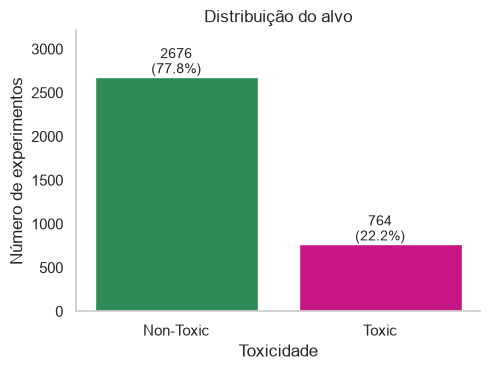

In [4]:
print(df["Toxicity"].value_counts(dropna=False))

contagem = df["Toxicity"].value_counts()
cores = [COR_NAO_TOXICO if "non" in str(k).lower() else COR_TOXICO for k in contagem.index]

fig, ax = plt.subplots(figsize=(5, 3.8))
barras = ax.bar(contagem.index, contagem.values, color=cores)
for b, v in zip(barras, contagem.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v / contagem.sum():.1%})",
            ha="center", va="bottom")
ax.set_ylim(0, contagem.max() * 1.2)
ax.set_xlabel("Toxicidade")
ax.set_ylabel("Número de experimentos")
ax.set_title("Distribuição do alvo")
plt.tight_layout()
plt.show()

**Interpretação:** As classes são **desbalanceadas**: 764 dos 3440 experimentos (22%) são tóxicos e 2676 (78%) são não tóxicos (valores antes da remoção de duplicatas), cerca de **3,5 não tóxicos para cada tóxico**. Um modelo que sempre responde "não tóxico" acertaria **78%** (a **acurácia** é a fração de previsões corretas) sem aprender nada, por isso **a acurácia sozinha não serve aqui**. Essa é a razão de otimizar a **AUC-ROC** (probabilidade do modelo preterir uma classificação a outra) e de reportar também acurácia balanceada, F1 e revocação (*recall*), que olham a classe tóxica (minoritária) separadamente. Também justifica testar `class_weight` e `scale_pos_weight`, que dão mais peso aos exemplos tóxicos durante o treino.

Agora as **variáveis numéricas** (propriedades físico-químicas e quânticas, dose e tempo de exposição).

Numéricas: ['Core_size', 'Hydro_size', 'Surface_charge', 'Surface_area', 'Formation_enthalpy', 'Conduction_band', 'Valence_band', 'Electronegativity', 'Exposure_time', 'Exposure_dose']


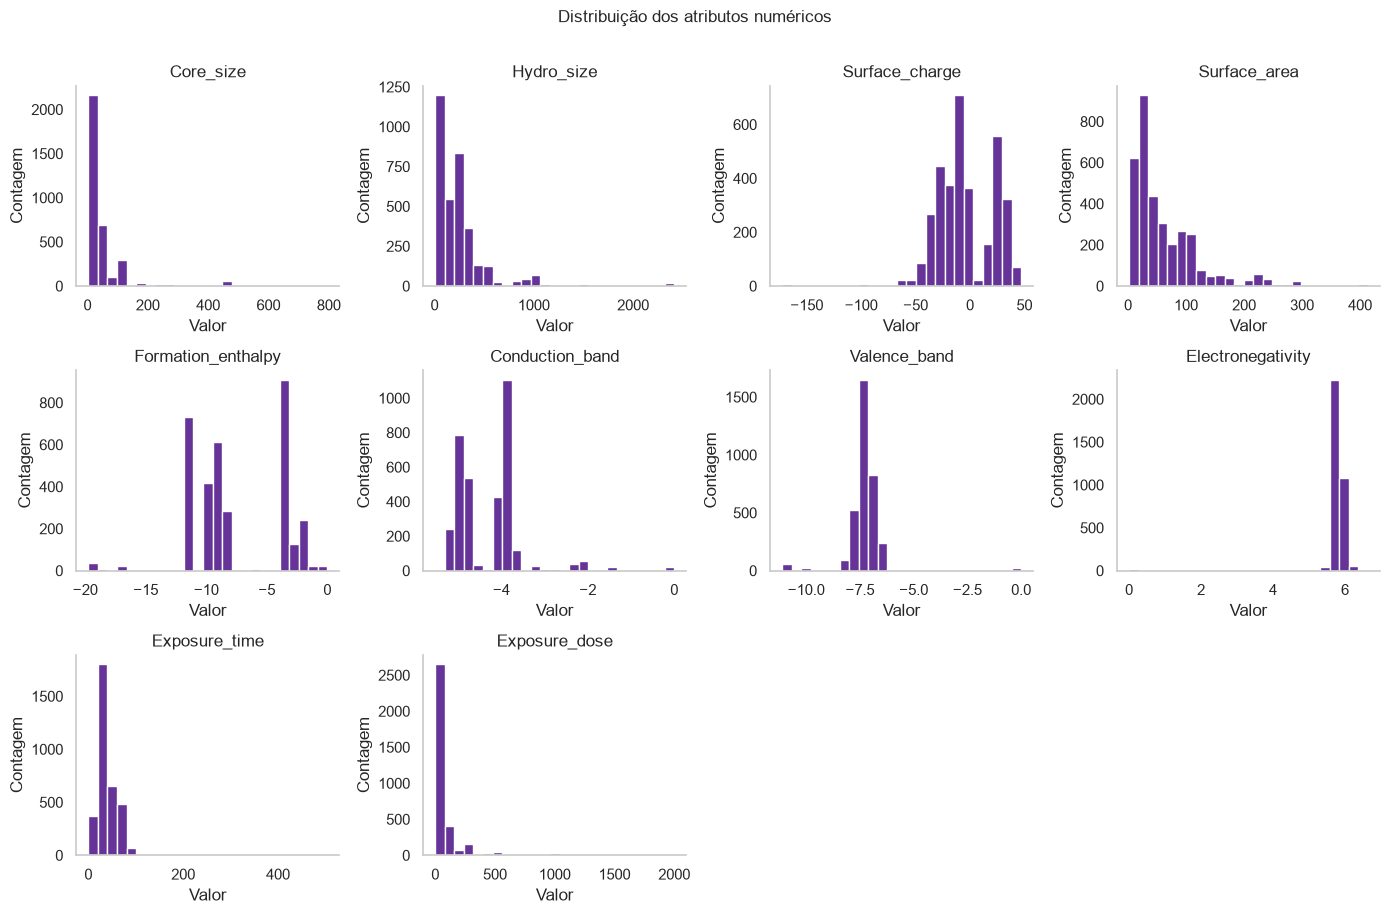

In [5]:
num_cols_all = df.select_dtypes(include="number").columns.tolist()
print("Numéricas:", num_cols_all)

ncols = 4
nrows = int(np.ceil(len(num_cols_all) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3 * nrows))
axes = axes.ravel()
for ax, col in zip(axes, num_cols_all):
    ax.hist(df[col].dropna(), bins=25, color=COR_PRIMARIA, edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Contagem")
for ax in axes[len(num_cols_all):]:
    ax.set_visible(False)
fig.suptitle("Distribuição dos atributos numéricos", y=1.01)
plt.tight_layout()
plt.show()

**Interpretação:** Quase todos os atributos têm distribuição **assimétrica à direita** (muitos valores pequenos e uma cauda longa): `Core_size` (maioria abaixo de ~100, com cauda até ~800), `Hydro_size`, `Surface_area`, `Exposure_time` e, principalmente, `Exposure_dose` (maioria perto de zero, com valores até ~2000). `Surface_charge` é a mais diferente: concentra-se entre cerca de −50 e 0 e tem um segundo grupo entre +20 e +40, isto é, partículas de carga negativa e positiva. `Formation_enthalpy` e `Conduction_band` têm picos isolados, o esperado para propriedades do **material**, que se repetem em muitas linhas porque há poucos materiais distintos. Há ainda um pequeno grupo de valores próximos de zero em `Valence_band` e `Conduction_band`, que contrasta com o restante e podem ser valores de preenchimento ou um material atípico.

**Impactos na modelagem:** *árvores* (Random Forest e XGBoost) só comparam limiares e *não são afetadas por assimetria*. A *regressão logística e o SVM dependem de distâncias e escala*; o `StandardScaler` corrige a escala, mas não a assimetria, então uma *transformação logarítmica de dose, tamanhos e área poderia ajudar esses dois modelos*.


Em seguida, a **correlação entre os atributos numéricos**. Correlações altas indicam redundância (algo que modelos lineares e SVM sentem mais que árvores).

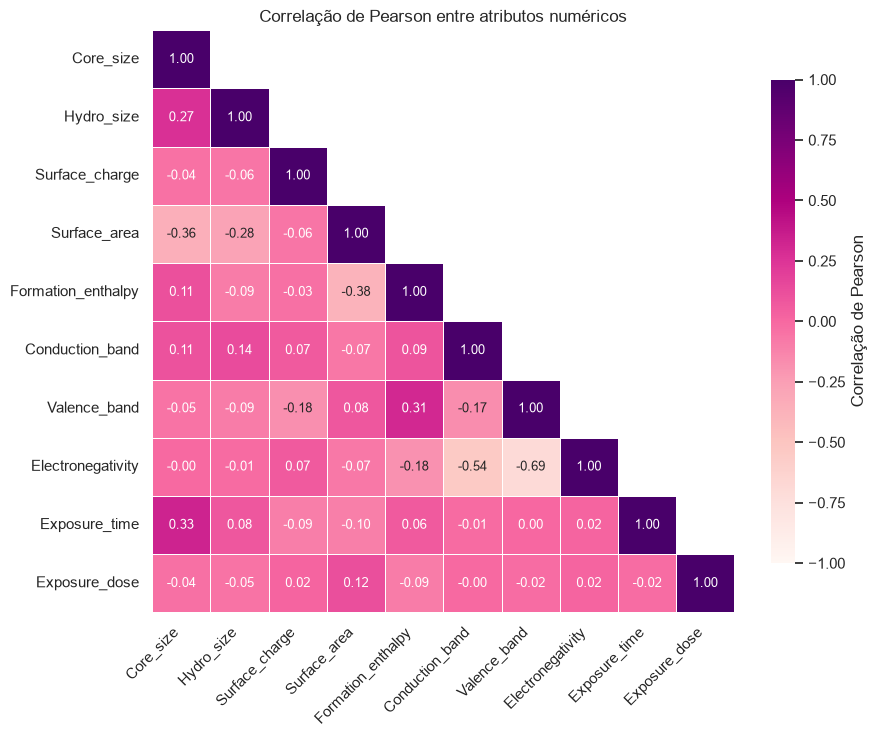

In [6]:
corr = df[num_cols_all].corr()
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)   # esconde o triângulo repetido

plt.figure(figsize=(9, 7.5))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", annot_kws={"size": 9},
            cmap=CMAP_CORR, vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Correlação de Pearson", "shrink": 0.8})
plt.title("Correlação de Pearson entre atributos numéricos")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretação:** A maioria das correlações é fraca (|r| < 0,4), então **os atributos trazem informação em boa parte complementar**. As exceções fazem sentido físico: `Valence_band` × `Electronegativity` (r = −0,69) e `Conduction_band` × `Electronegativity` (r = −0,54), já que as energias de banda de óxidos metálicos costumam ser estimadas a partir da eletronegatividade; e `Surface_area` × `Formation_enthalpy` (r = −0,38), `Core_size` (r = −0,36) e `Hydro_size` (r = −0,28), pois partículas maiores têm menos área de superfície por massa. `Exposure_dose` não se correlaciona com praticamente nada (|r| ≤ 0,12), o que sugere que a dose variou de forma independente das propriedades do material. Não há correlações próximas de ±1, logo **não há redundância extrema**; ainda assim, **bandas e eletronegatividade carregam informação parecida e devem dividir a importância entre si** (Seção 10).


Agora as **variáveis categóricas**: quantas categorias cada uma tem. Colunas com cardinalidade muito alta (como `Cell_name`) criariam centenas de colunas após o *one-hot* e favoreceriam *overfitting*.

In [7]:
cat_cols_all = df.select_dtypes(exclude="number").columns.drop("Toxicity").tolist()
print(df[cat_cols_all].nunique().sort_values(ascending=False))

Cell_name        87
Cell_origin      27
Assay            25
Material_type    24
Cell_species      9
Cell_type         3
dtype: int64


Por fim, a **taxa de toxicidade por categoria**, para ver quais fatores parecem mais associados ao alvo. Usaremos uma **versão binária do alvo (1 = tóxico)**, criada na próxima seção, *por isso a figura vem depois da limpeza*.

## **4. Limpeza e definição de grupos**

Foram utilizadas **três estratégias de limpeza**, todas aplicadas antes de qualquer divisão treino/teste e que **não usam o alvo**, portanto sem risco de vazamento:

1. **Remover duplicatas exatas.**
2. **Codificar o alvo como 0/1** (1 = tóxico). A célula imprime o mapeamento para conferência.
3. **Criar a coluna `group`**, que identifica o mesmo material experimental (tipo + tamanho de núcleo + tamanho hidrodinâmico + carga superficial). Ela só serve para dividir os dados; **não entra como atributo**.

Também removemos `Cell_name` (alta cardinalidade), mantendo `Cell_type`, `Cell_species` e `Cell_origin`, que descrevem a célula em nível mais geral.

In [8]:
df = df.drop_duplicates().reset_index(drop=True)

# Alvo binário: 1 = tóxico. Confira o mapeamento impresso abaixo.
t = df["Toxicity"].astype(str).str.lower().str.strip()
is_toxic = (~t.str.contains("non")) & (t.str.contains("toxic") | t.isin(["1", "1.0", "true", "yes"]))
df["y"] = is_toxic.astype(int)
print(pd.crosstab(df["Toxicity"], df["y"]))

group_cols = [c for c in ["Material_type", "Core_size", "Hydro_size", "Surface_charge"] if c in df.columns]
df["group"] = df[group_cols].astype(str).agg("|".join, axis=1)
print("\nLinhas:", len(df), "| Materiais distintos (grupos):", df["group"].nunique())
print("Experimentos por grupo (mediana):", df.groupby("group").size().median())

y             0    1
Toxicity            
Non-Toxic  2538    0
Toxic         0  743

Linhas: 3281 | Materiais distintos (grupos): 232
Experimentos por grupo (mediana): 8.0


Agora a figura prometida: a **taxa de toxicidade por categoria**.

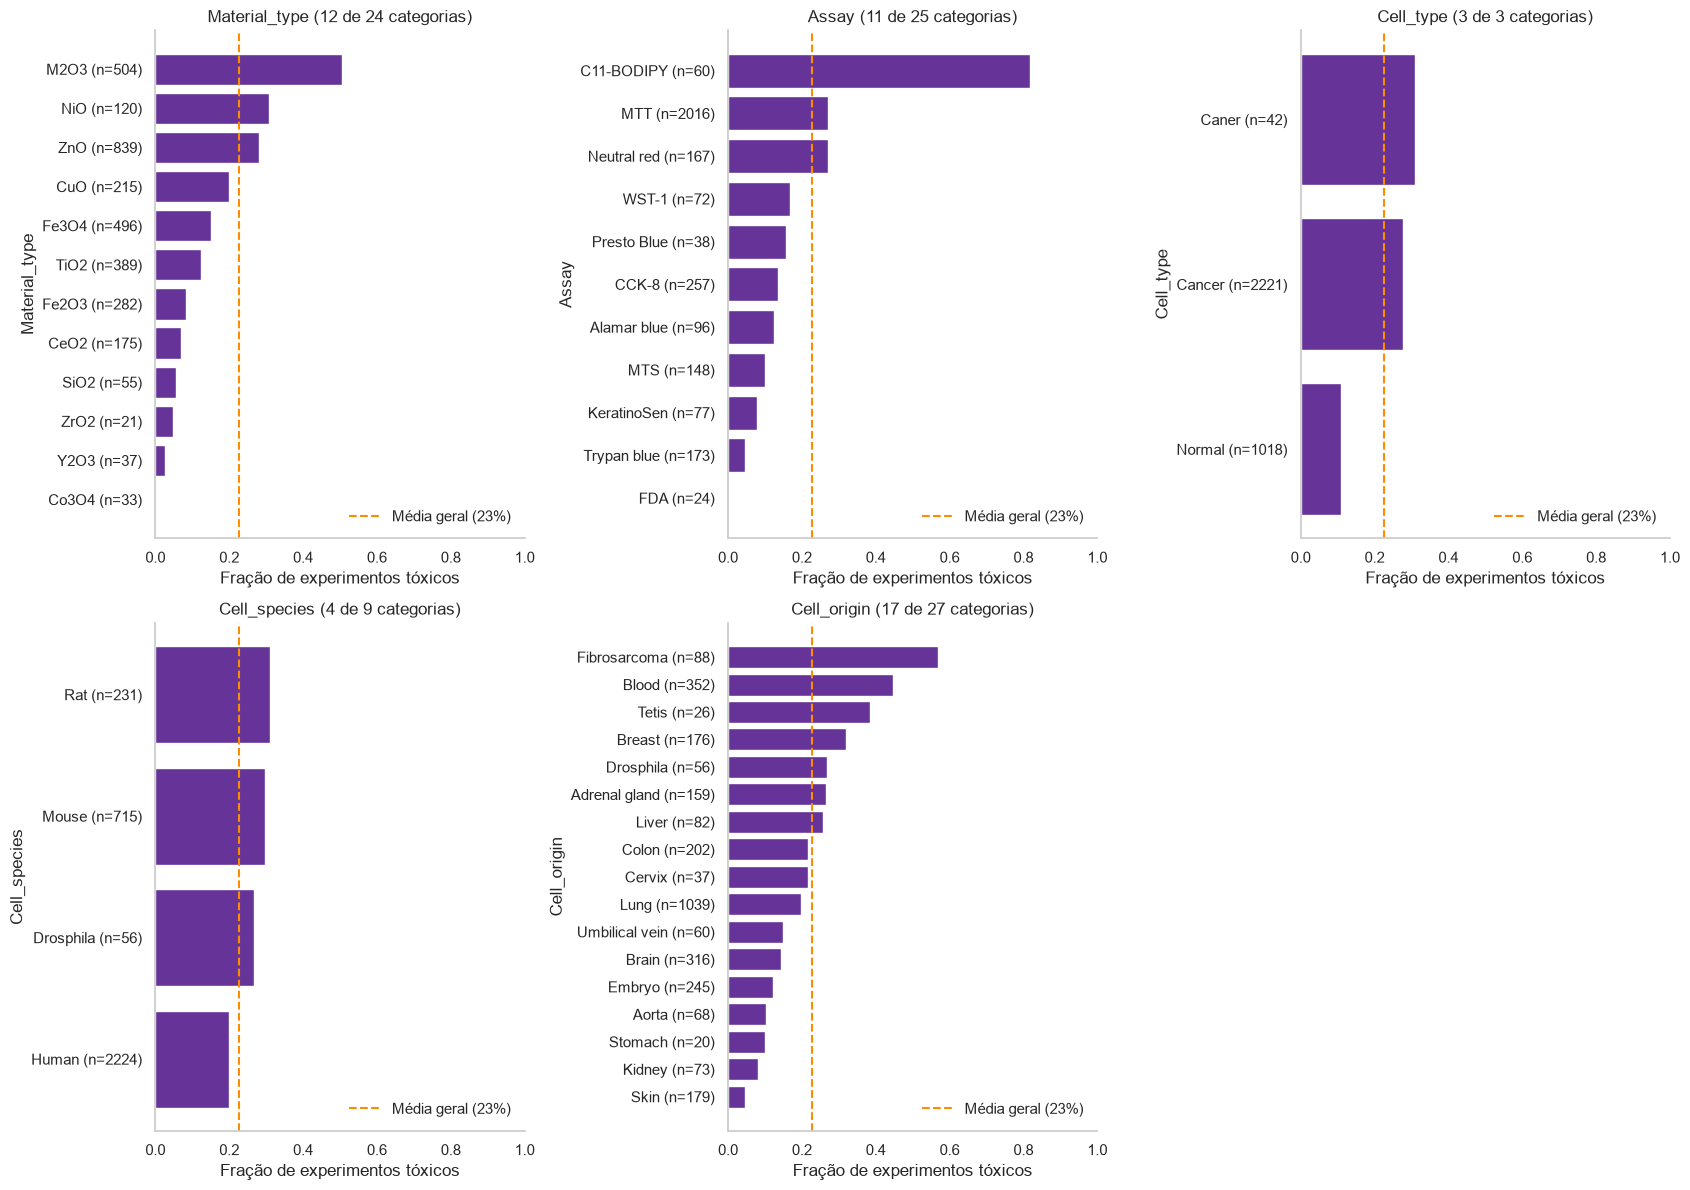

In [9]:
MIN_N_CATEGORIA = 20   # categorias com menos experimentos que isso ficam fora (use 0 para mostrar todas)

cat_plot = [c for c in ["Material_type", "Assay", "Cell_type", "Cell_species", "Cell_origin"] if c in df.columns]
taxa_global = df["y"].mean()

ncols = 3
nrows = int(np.ceil(len(cat_plot) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(17, 6 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, c in zip(axes, cat_plot):
    g = df.groupby(c)["y"].agg(["mean", "size"])
    g = g[g["size"] >= MIN_N_CATEGORIA].sort_values("mean")
    rotulos = [f"{cat} (n={n})" for cat, n in zip(g.index, g["size"])]
    ax.barh(rotulos, g["mean"], color=COR_PRIMARIA)
    ax.axvline(taxa_global, color=COR_DESTAQUE, linestyle="--", label=f"Média geral ({taxa_global:.0%})")
    ax.set_xlim(0, 1)
    ax.set_xlabel("Fração de experimentos tóxicos")
    ax.set_ylabel(c)
    ax.set_title(f"{c} ({len(g)} de {df[c].nunique()} categorias)")
    ax.legend(loc="lower right", frameon=False)
for ax in axes[len(cat_plot):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**Interpretação:** A taxa de toxicidade **se afasta bastante da média geral** (≈ 23%, indicada pela linha tracejada) em várias categorias de ensaio, de célula e de material, o que indica que **o contexto biológico ajuda a distinguir experimentos tóxicos de não tóxicos**. Aqui observamos *dois pontos de atenção*: primeiro, **categorias com poucos experimentos produzem taxas extremas** (0% ou 100%) pouco confiáveis, por isso cada barra mostra o `n` e o gráfico omite categorias abaixo de `MIN_N_CATEGORIA`; segundo, **a associação é descritiva**, não causal: *um ensaio ou tipo de célula pode parecer mais tóxico simplesmente por ter sido usado com doses mais altas ou com certos materiais*. A taxa por categoria é só um primeiro olhar; **quem mede o quanto o modelo depende de cada atributo é a importância por permutação** (Seção 10).

## **5. Divisão treino/teste sem vazamento**

**Separamos 20% dos materiais** (não das linhas) **para o teste**, com `GroupShuffleSplit`. O conjunto de teste só será usado **uma vez**, no final. Toda escolha de hiperparâmetros usa apenas o treino, via validação cruzada também agrupada.

In [10]:
drop_cols = ["Toxicity", "y", "group", "Cell_name"]
features = [c for c in df.columns if c not in drop_cols]
X, y, groups = df[features], df["y"], df["group"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx])), "Vazamento de grupos!"
print(f"Treino: {len(X_train)} linhas | Teste: {len(X_test)} linhas")
print(f"Fração de tóxicos — treino: {y_train.mean():.2f} | teste: {y_test.mean():.2f}")

Treino: 2556 linhas | Teste: 725 linhas
Fração de tóxicos — treino: 0.24 | teste: 0.16


O `assert` **garante que nenhum material aparece nos dois conjuntos**. Frações de tóxicos parecidas indicam que o teste é representativo.

Para a **validação cruzada interna (CV)** usaremos `StratifiedGroupKFold` (5 dobras): *mantém materiais inteiros na mesma dobra* **e** *tenta preservar a proporção das classes*.

In [11]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

## **6. Pré-processamento e métrica de desempenho**

**Pré-processamento dentro do pipeline:** inclui imputação, normalização e *one-hot* aplicados dentro de um `Pipeline` do `scikit-learn`, **ajustado apenas nos dados de treino de cada dobra**. Assim, nenhuma estatística do conjunto de validação/teste (média, desvio, categorias) vaza para o ajuste.

- **Classes Numéricas:** imputação pela mediana + `StandardScaler` (importante para o SVM e a regressão logística; inofensivo para árvores).
- **Classes Categóricas:** imputação pela moda + `OneHotEncoder` (categorias desconhecidas são ignoradas).

**Métrica:** Otimizaremos a **AUC-ROC** (área sob a curva ROC) que *mede quão bem o modelo ordena experimentos tóxicos acima dos não tóxicos*, independe de limiar de decisão e é menos enganosa que a acurácia caso as classes sejam desbalanceadas. **No teste final reportaremos também acurácia balanceada, F1, precisão e revocação (*recall*)**.

In [12]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

def make_preprocessor():
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

def cv_auc(pipe):
    return cross_val_score(pipe, X_train, y_train, groups=g_train, cv=cv,
                           scoring="roc_auc", n_jobs=-1)

Numéricas: ['Core_size', 'Hydro_size', 'Surface_charge', 'Surface_area', 'Formation_enthalpy', 'Conduction_band', 'Valence_band', 'Electronegativity', 'Exposure_time', 'Exposure_dose']
Categóricas: ['Material_type', 'Assay', 'Cell_species', 'Cell_origin', 'Cell_type']


## **7. Baselines**

Um baseline dá o "piso" de comparação: se um modelo sofisticado não supera um baseline simples, ele não está agregando valor. Nestes dados, usamos dois:

- **DummyClassifier** (sempre prevê a classe mais frequente): AUC esperada ≈ 0,5.
- **Regressão Logística** com hiperparâmetros padrão, sem otimização.

In [13]:
baselines = {
    "Dummy (classe majoritária)": Pipeline([("prep", make_preprocessor()),
                                            ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Regressão Logística (padrão)": Pipeline([("prep", make_preprocessor()),
                                              ("clf", LogisticRegression(max_iter=2000))])}

cv_scores = {name: cv_auc(p) for name, p in baselines.items()}
for name, s in cv_scores.items():
    print(f"{name}: AUC-ROC CV = {s.mean():.3f} ± {s.std():.3f}")

Dummy (classe majoritária): AUC-ROC CV = 0.500 ± 0.000
Regressão Logística (padrão): AUC-ROC CV = 0.713 ± 0.118


**Interpretação:** O `DummyClassifier` tem **AUC-ROC de exatamente** `0,500 ± 0,000`, **como esperado**: ele prevê sempre a mesma resposta, não consegue ordenar experimentos e representa o desempenho de "chute". A `Regressão Logística`, sem ajustes, chega a `0,713`, **acima do acaso, mas com desvio-padrão alto** (`± 0,118`): em uma das dobras o desempenho fica por volta de 0,49 (visível no boxplot da Seção 9), isto é, **o modelo linear quase não generaliza para alguns materiais**. Isso **sugere que a relação entre atributos e toxicidade é não linear** (por exemplo, efeitos que só aparecem acima de certa dose ou combinando dose e material), algo que um modelo linear captura mal. **O valor de referência a ser superado pelos modelos otimizados é** `AUC-ROC ≈ 0,71`.

## **8. Otimização de hiperparâmetros com Optuna**

O `Optuna` faz **busca bayesiana de hiperparâmetros** (Akiba et al., 2019): em vez de testar combinações ao acaso, usa o histórico de tentativas (estimador TPE) para propor combinações promissoras. **Cada tentativa treina o pipeline completo com 5 dobras agrupadas somente no treino** e **devolve a AUC-ROC média**, que o `Optuna` maximiza. **Nenhuma informação do conjunto de teste é usada na escolha.**

Três algoritmos de famílias diferentes, mais dois pipelines adicionais, nas `Seções 8.3.1 e 8.3.2`, sendo 5 ao total, foram aplicados:

- **Random Forest:** muitas árvores independentes (bagging), robusto e com poucos ajustes necessários.
- **XGBoost:** árvores em sequência, cada uma corrigindo o erro das anteriores (boosting com regularização) (Chen e Guestrin, 2016).
- **SVM (kernel RBF):** busca a fronteira de maior margem em um espaço transformado pelo kernel, sensível à escala dos dados (por isso a normalização).
- **Regressão logística com pipeline otimizado:** modelo linear cujo pré-processamento também é otimizado (transformação logarítmica de atributos assimétricos e termos de interação), para testar se a não linearidade pode ser capturada sem abandonar o modelo linear.
- **kNN (k vizinhos mais próximos):** classifica cada experimento pela maioria entre os `k` mais parecidos no treino; não aprende parâmetros, apenas guarda os dados.

Para cada hiperparâmetro, **a faixa de busca é justificada nos comentários do código**.

### **8.1 Random Forest**

Hiperparâmetros mais influentes: **número de árvores** (`n_estimators`, mais árvores estabilizam, com retorno decrescente), **profundidade** (`max_depth`, controla overfitting), tamanho mínimo de folha/divisão (suavizam a árvore) e `max_features` (diversidade entre árvores). Em `class_weight`, "`balanced`" compensa um possível desbalanceamento.

In [14]:
def objective_rf(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 600),          # estabiliza a partir de ~100-500
        max_depth=trial.suggest_int("max_depth", 3, 30),                   # raso = underfit; fundo = overfit
        min_samples_split=trial.suggest_int("min_samples_split", 2, 30),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20),     # folhas maiores suavizam
        max_features=trial.suggest_float("max_features", 0.1, 1.0),        # fração de atributos por divisão
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]))
	
    pipe = Pipeline([("prep", make_preprocessor()),
                     ("clf", RandomForestClassifier(random_state=SEED, n_jobs=1, **params))])
    return cv_auc(pipe).mean()

study_rf = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_rf.optimize(objective_rf, n_trials=N_TRIALS)
print(f"Melhor AUC-ROC (CV): {study_rf.best_value:.3f}")
print(study_rf.best_params)

Melhor AUC-ROC (CV): 0.848
{'n_estimators': 425, 'max_depth': 16, 'min_samples_split': 4, 'min_samples_leaf': 2, 'max_features': 0.4107528532008015, 'class_weight': 'balanced'}


### **8.2 XGBoost**

Aqui os hiperparâmetros influentes são: `learning_rate` (passo de cada árvore; menor = mais estável, mas exige mais árvores, por isso escala logarítmica), `max_depth`, `subsample`/`colsample_bytree` (amostragem de linhas e colunas, reduzem overfitting) e as regularizações `reg_alpha` (L1) e `reg_lambda` (L2) sobre os pesos das folhas. `scale_pos_weight` permite compensar desbalanceamento.

In [15]:
def objective_xgb(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 600),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 10),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),    # L1
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),  # L2
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 0.5, 3.0))
	
    pipe = Pipeline([("prep", make_preprocessor()),
                     ("clf", XGBClassifier(random_state=SEED, n_jobs=1, eval_metric="logloss", **params))])
    return cv_auc(pipe).mean()

study_xgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb.optimize(objective_xgb, n_trials=N_TRIALS)
print(f"Melhor AUC-ROC (CV): {study_xgb.best_value:.3f}")
print(study_xgb.best_params)

Melhor AUC-ROC (CV): 0.853
{'n_estimators': 529, 'learning_rate': 0.05762563343824775, 'max_depth': 6, 'subsample': 0.8200887199126644, 'colsample_bytree': 0.476076711214466, 'min_child_weight': 2, 'reg_alpha': 0.003399430169400674, 'reg_lambda': 0.02393714875114355, 'scale_pos_weight': 2.5077008066993733}


### **8.3 SVM com kernel RBF**

Os dois hiperparâmetros centrais são `C` (penalidade por erro: alto = margem estreita e risco de overfitting) e `gamma` (alcance de cada exemplo no kernel RBF: alto = fronteira muito local). **Ambos variam em ordens de grandeza, daí a escala logarítmica**. Como o SVM é o mais lento, mantemos o mesmo número de tentativas, mas o tempo total será maior.

In [16]:
def objective_svm(trial):
    params = dict(
        C=trial.suggest_float("C", 1e-2, 1e3, log=True),
        gamma=trial.suggest_float("gamma", 1e-4, 1e1, log=True),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]))
	
    pipe = Pipeline([("prep", make_preprocessor()),
                     ("clf", SVC(kernel="rbf", **params))])
    return cv_auc(pipe).mean()

study_svm = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_svm.optimize(objective_svm, n_trials=N_TRIALS)
print(f"Melhor AUC-ROC (CV): {study_svm.best_value:.3f}")
print(study_svm.best_params)

Melhor AUC-ROC (CV): 0.839
{'C': 5.6026918262700285, 'gamma': 0.5689741478122241, 'class_weight': 'balanced'}


### **8.3.1 Regressão logística com pipeline otimizado**

Usamos a regressão logística em duas versões: a do baseline (sem ajustes) e esta, com pipeline próprio. Aqui o `Optuna` decide, além da regularização, **como pré-processar os atributos numéricos**:

- `C`: inverso da força da regularização L2 (menor `C` = coeficientes mais contidos, menos *overfitting*); escala logarítmica por variar em ordens de grandeza.
- `class_weight`: dá mais peso à classe tóxica (minoritária) ou não.
- `log_assimetricos`: aplica `log(1 + x)` aos atributos muito assimétricos (a lista é calculada **só no treino e sem usar o alvo**), o que reduz o efeito da cauda longa vista na seção 3.
- `grau_polinomial`: com grau 2, **o modelo ganha termos de interação e quadráticos entre os atributos numéricos** (por exemplo, dose × entalpia), o que permite *efeitos não lineares* mantendo um modelo linear nos coeficientes.

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures

# atributos numéricos assimétricos e não negativos (definidos apenas com o treino, sem o alvo)
cols_log = [c for c in num_cols if X_train[c].min() >= 0 and X_train[c].skew() > 1]
idx_log = [num_cols.index(c) for c in cols_log]
print("Atributos candidatos a log(1 + x):", cols_log)

def aplicar_log(X_, idx):
    X_ = np.array(X_, dtype=float, copy=True)
    X_[:, idx] = np.log1p(np.clip(X_[:, idx], 0, None))
    return X_

def make_preprocessor_log(usar_log, grau):
    etapas = [("imp", SimpleImputer(strategy="median"))]
    if usar_log:
        etapas.append(("log", FunctionTransformer(aplicar_log, kw_args={"idx": idx_log})))
    etapas.append(("sc", StandardScaler()))
    if grau > 1:
        etapas.append(("poly", PolynomialFeatures(degree=grau, include_bias=False)))
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", Pipeline(etapas), num_cols), ("cat", cat, cat_cols)])

def build_lr(params):
    p = dict(params)
    usar_log, grau = p.pop("log_assimetricos"), p.pop("grau_polinomial")
    return Pipeline([("prep", make_preprocessor_log(usar_log, grau)),
                     ("clf", LogisticRegression(max_iter=5000, **p))])

def objective_lr(trial):
    params = dict(
        C=trial.suggest_float("C", 1e-4, 1e2, log=True),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
        log_assimetricos=trial.suggest_categorical("log_assimetricos", [False, True]),
        grau_polinomial=trial.suggest_categorical("grau_polinomial", [1, 2]))
	
    return cv_auc(build_lr(params)).mean()

study_lr = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_lr.optimize(objective_lr, n_trials=N_TRIALS)
print(f"Melhor AUC-ROC (CV): {study_lr.best_value:.3f}")
print(study_lr.best_params)

Atributos candidatos a log(1 + x): ['Core_size', 'Hydro_size', 'Surface_area', 'Exposure_time', 'Exposure_dose']
Melhor AUC-ROC (CV): 0.841
{'C': 0.14455439922127755, 'class_weight': None, 'log_assimetricos': True, 'grau_polinomial': 2}


**Interpretação:** a regressão logística padrão (baseline) teve AUC-ROC de CV ≈ 0,71. Com o pipeline otimizado ela chegou a **0,841** (`C` ≈ 0,144, `class_weight` = None, `log_assimetricos` = True, `grau_polinomial` = 2), um ganho de ≈ 0,13, e ficou no mesmo patamar de Random Forest (≈ 0,848), XGBoost (≈ 0,853) e SVM (0,839); essas diferenças são pequenas frente à variação entre dobras. Pela importância dos hiperparâmetros (seção 8.4), o ganho vem quase todo da **regularização**: `C` concentra ≈ 0,98 da importância, e o valor escolhido é menor que o padrão (1), ou seja, regularização mais forte, o que ajuda a evitar overfitting entre materiais. Já `grau_polinomial` e `log_assimetricos` têm importância próxima de zero: o Optuna escolheu grau 2 e logaritmo, mas o desempenho quase não depende dessas escolhas, então interações e transformação logarítmica não explicam a melhora. `class_weight` também pesou pouco, o que é esperado, pois a AUC avalia a ordenação e não o limiar de decisão.

### **8.3.2 k vizinhos mais próximos (kNN)**

O **kNN** classifica um experimento pela maioria entre os `k` experimentos mais parecidos do treino. Como depende de distâncias, usa os atributos normalizados e codificados em *one-hot*. Hiperparâmetros otimizados:

- `n_neighbors` (`k`): poucos vizinhos = fronteira irregular e sensível a ruído; muitos = fronteira suave, mas pode perder detalhes (faixa de 1 a 60, pois o treino tem ~2500 linhas).
- `weights`: `uniform` (todos os vizinhos valem igual) ou `distance` (vizinhos mais próximos pesam mais).
- `p`: tipo de distância de Minkowski (1 = Manhattan, 2 = Euclidiana).
- `log_assimetricos`: mesma transformação logarítmica da seção anterior, importante porque a distância é sensível à cauda longa de dose e tamanhos.

In [18]:
def build_knn(params):
    p = dict(params)
    usar_log = p.pop("log_assimetricos")
    return Pipeline([("prep", make_preprocessor_log(usar_log, 1)),
                     ("clf", KNeighborsClassifier(n_jobs=1, **p))])

def objective_knn(trial):
    params = dict(
        n_neighbors=trial.suggest_int("n_neighbors", 1, 60),
        weights=trial.suggest_categorical("weights", ["uniform", "distance"]),
        p=trial.suggest_categorical("p", [1, 2]),
        log_assimetricos=trial.suggest_categorical("log_assimetricos", [False, True]))
	
    return cv_auc(build_knn(params)).mean()

study_knn = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_knn.optimize(objective_knn, n_trials=N_TRIALS)
print(f"Melhor AUC-ROC (CV): {study_knn.best_value:.3f}")
print(study_knn.best_params)

Melhor AUC-ROC (CV): 0.844
{'n_neighbors': 19, 'weights': 'distance', 'p': 2, 'log_assimetricos': True}


**Interpretação:** Com o pipeline otimizado, o kNN chegou a AUC-ROC de CV de **0,844** (`n_neighbors` = 19, `weights` = distance, `p` = 2, `log_assimetricos` = True). Isso supera o baseline (≈ 0,71) em ≈ 0,13 e fica no mesmo patamar dos demais modelos (Random Forest ≈ 0,848, XGBoost ≈ 0,853, SVM ≈ 0,839 e regressão logística otimizada 0,841); como as diferenças são pequenas frente à variação entre dobras, não dá para dizer que algum é melhor. `n_neighbors` concentra ≈ 0,97 da importância: o desempenho do kNN depende quase só de quantos vizinhos são usados. O `k = 19` é um valor intermediário (faixa de 1 a 60): usa vizinhos suficientes para suavizar o ruído, mas ainda é local. `weights`, `p` e `log_assimetricos` pesam perto de zero, então ponderar pela distância, usar distância euclidiana ou aplicar o logaritmo muda pouco o resultado.

### **8.4 Diagnóstico da otimização**

Dois gráficos por algoritmo: (i) a melhor AUC encontrada até cada tentativa (se a curva ainda sobe no final, 100 tentativas podem ser poucas) e (ii) a **importância dos hiperparâmetros** segundo o `Optuna` (quais ajustes mais afetaram o desempenho), o que ajuda a justificar se a faixa de busca foi adequada.

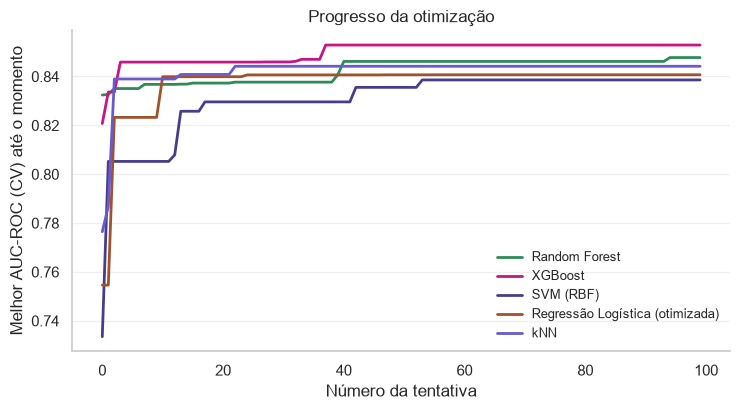

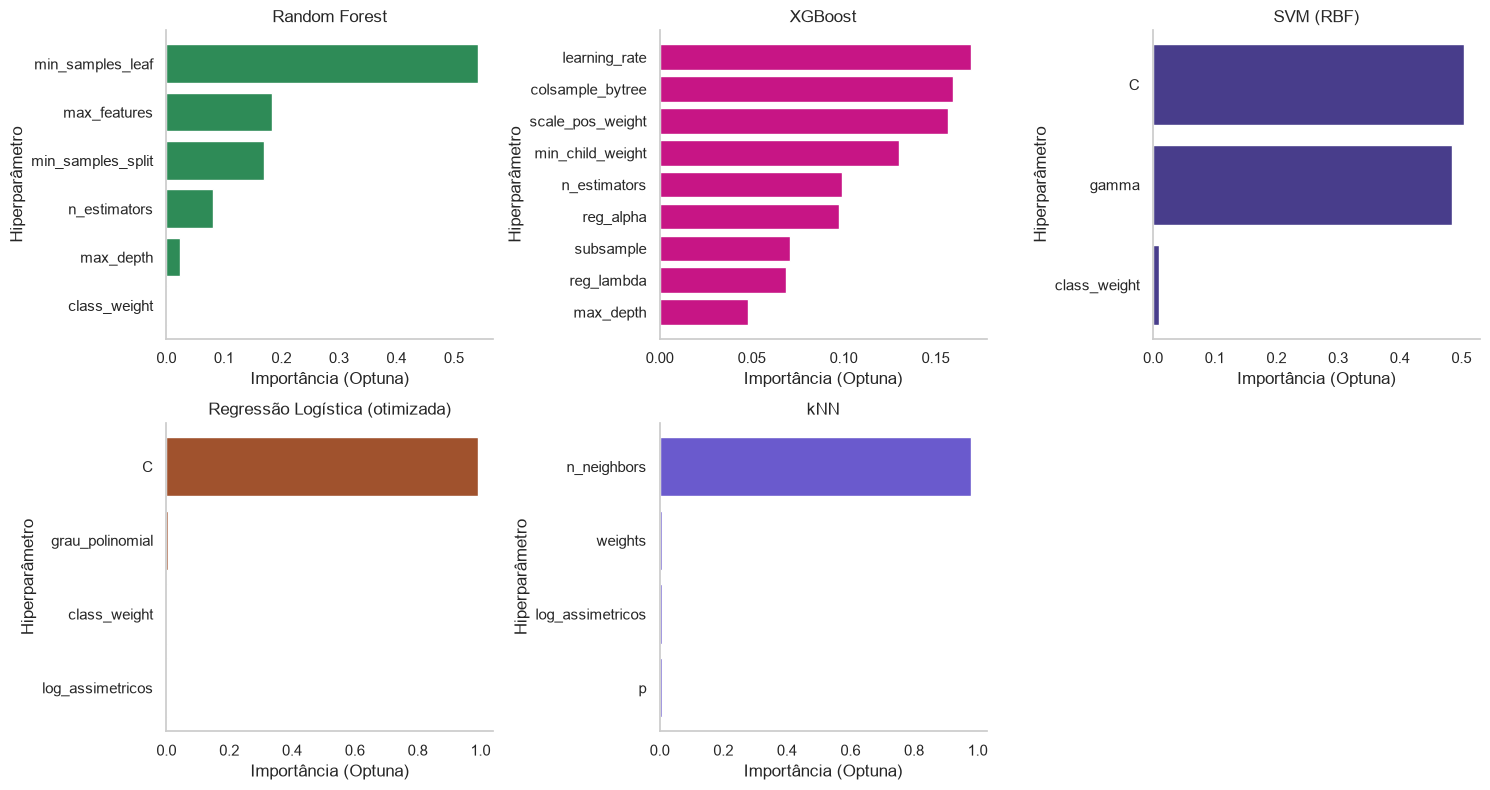

In [19]:
studies = {"Random Forest": study_rf, "XGBoost": study_xgb, "SVM (RBF)": study_svm,
           "Regressão Logística (otimizada)": study_lr, "kNN": study_knn}

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, st in studies.items():
    ax.plot(np.maximum.accumulate([t.value for t in st.trials]), label=name,
            color=CORES_MODELOS[name], linewidth=2)
ax.set_xlabel("Número da tentativa")
ax.set_ylabel("Melhor AUC-ROC (CV) até o momento")
ax.set_title("Progresso da otimização")
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

ncols = 3
nrows = int(np.ceil(len(studies) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.ravel()
for ax, (name, st) in zip(axes, studies.items()):
    imp = pd.Series(optuna.importance.get_param_importances(st)).sort_values()
    ax.barh(imp.index, imp.values, color=CORES_MODELOS[name])
    ax.set_xlabel("Importância (Optuna)")
    ax.set_ylabel("Hiperparâmetro")
    ax.set_title(name)
for ax in axes[len(studies):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**Interpretação:** **Observa-se uma convergência nos resultados obtidos;** os estudos de Random Forest, XGBoost e SVM estabilizam bem antes da tentativa 100: o Random Forest chega a `≈ 0,848` por volta da tentativa 40, o XGBoost a `≈ 0,853` perto da 37 e o SVM a `≈ 0,839` perto da 53, e as curvas ficam planas depois disso. **Mais tentativas provavelmente trariam ganhos mínimos**. A diferença entre esses três (`≈ 0,01 de AUC`) é pequena frente à variação entre dobras (Seção 9), então **a validação cruzada sozinha não permite afirmar que um é melhor que outro**.

**Importância dos hiperparâmetros** (mede o quanto o desempenho é sensível ao hiperparâmetro, não a direção do efeito). No Random Forest, `min_samples_leaf` domina (≈ 0,54), seguido de `max_features` e `min_samples_split` (≈ 0,17 a 0,18); `max_depth` e `class_weight` quase não importam. O melhor `min_samples_leaf` foi 2, perto do limite inferior da faixa (1 a 20), sugerindo que folhas pequenas funcionam melhor. No XGBoost a importância é distribuída (`learning_rate`, `colsample_bytree` e `scale_pos_weight` em torno de 0,16): nenhum ajuste isolado manda, e o melhor `scale_pos_weight` (≈ 2,5) ficou perto do limite superior (3,0), coerente com o desbalanceamento de ≈ 3,5 para 1; vale testar uma faixa maior em trabalhos futuros. No SVM, `C` e `gamma` concentram quase toda a importância (≈ 0,5 cada) e o melhor par (C ≈ 5,6; gamma ≈ 0,57) ficou no interior da faixa, o que indica que a faixa de busca foi adequada; `class_weight` quase não pesou.

## **9. Comparação final dos modelos**

Montamos os pipelines com os melhores hiperparâmetros e comparamos de duas formas:

1. **Validação cruzada agrupada no treino** (mesmas 5 dobras para todos): mostra a variabilidade do desempenho entre dobras. **Os valores são levemente otimistas para os modelos otimizados, pois os hiperparâmetros foram escolhidos nessas mesmas dobras**.
2. **Conjunto de teste** (materiais nunca vistos), usado **uma única vez**: é a estimativa honesta de desempenho.

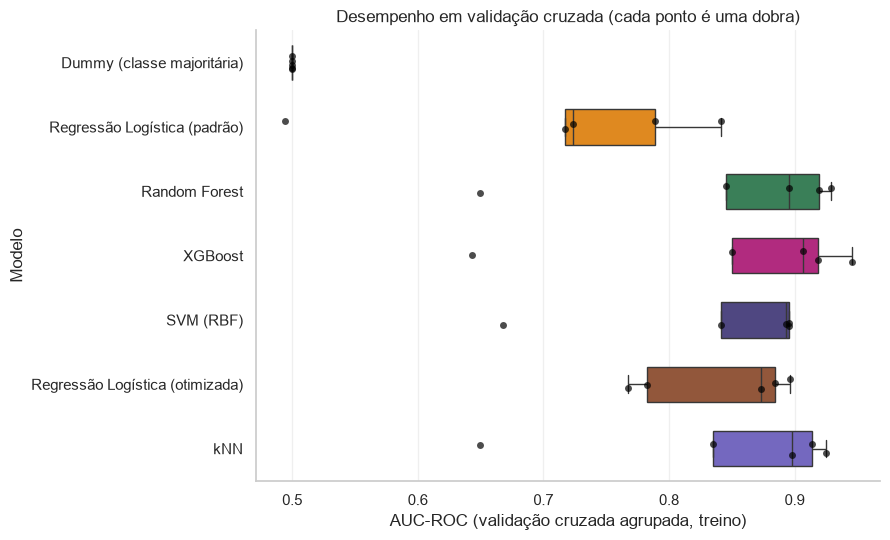

In [20]:
best = {
    "Random Forest": Pipeline([("prep", make_preprocessor()),
        ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1, **study_rf.best_params))]),
    "XGBoost": Pipeline([("prep", make_preprocessor()),
        ("clf", XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss", **study_xgb.best_params))]),
    "SVM (RBF)": Pipeline([("prep", make_preprocessor()),
        ("clf", SVC(kernel="rbf", **study_svm.best_params))]),
    "Regressão Logística (otimizada)": build_lr(study_lr.best_params),
    "kNN": build_knn(study_knn.best_params)}

models = {**baselines, **best}

for name, p in best.items():
    cv_scores[name] = cv_auc(p)

cv_df = pd.DataFrame(cv_scores)
cv_long = cv_df.melt(var_name="Modelo", value_name="AUC")
ordem = list(cv_df.columns)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=cv_long, x="AUC", y="Modelo", order=ordem, hue="Modelo", palette=CORES_MODELOS,
            legend=False, showfliers=False, width=0.55, ax=ax)
sns.stripplot(data=cv_long, x="AUC", y="Modelo", order=ordem, color="black", size=5, alpha=0.7, ax=ax)
ax.set_xlabel("AUC-ROC (validação cruzada agrupada, treino)")
ax.set_ylabel("Modelo")
ax.set_title("Desempenho em validação cruzada (cada ponto é uma dobra)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Agora o ajuste final no treino completo e a avaliação no teste. Para a AUC usamos o *score* contínuo do modelo (probabilidade ou distância à fronteira); para as demais métricas, a previsão de classe.

In [21]:
def score_of(pipe, X_):
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X_)[:, 1]
    return pipe.decision_function(X_)

rows, scores_test = [], {}
for name, p in models.items():
    p.fit(X_train, y_train)
    pred = p.predict(X_test)
    s = score_of(p, X_test)
    scores_test[name] = s
    rows.append({"Modelo": name,
                 "AUC-ROC": roc_auc_score(y_test, s),
                 "Acurácia balanceada": balanced_accuracy_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "Precisão": precision_score(y_test, pred, zero_division=0),
                 "Revocação": recall_score(y_test, pred)})

results = pd.DataFrame(rows).set_index("Modelo").round(3)
results

,AUC-ROC,Acurácia balanceada,F1,Precisão,Revocação
Modelo,,,,,
Dummy (classe majoritária),0.500,0.500,0.000,0.000,0.000
Regressão Logística (padrão),0.779,0.648,0.419,0.473,0.376
Random Forest,0.919,0.833,0.711,0.697,0.726
XGBoost,0.922,0.839,0.723,0.711,0.735
SVM (RBF),0.859,0.666,0.456,0.528,0.402
Regressão Logística (otimizada),0.862,0.765,0.598,0.581,0.615
kNN,0.914,0.784,0.683,0.795,0.598


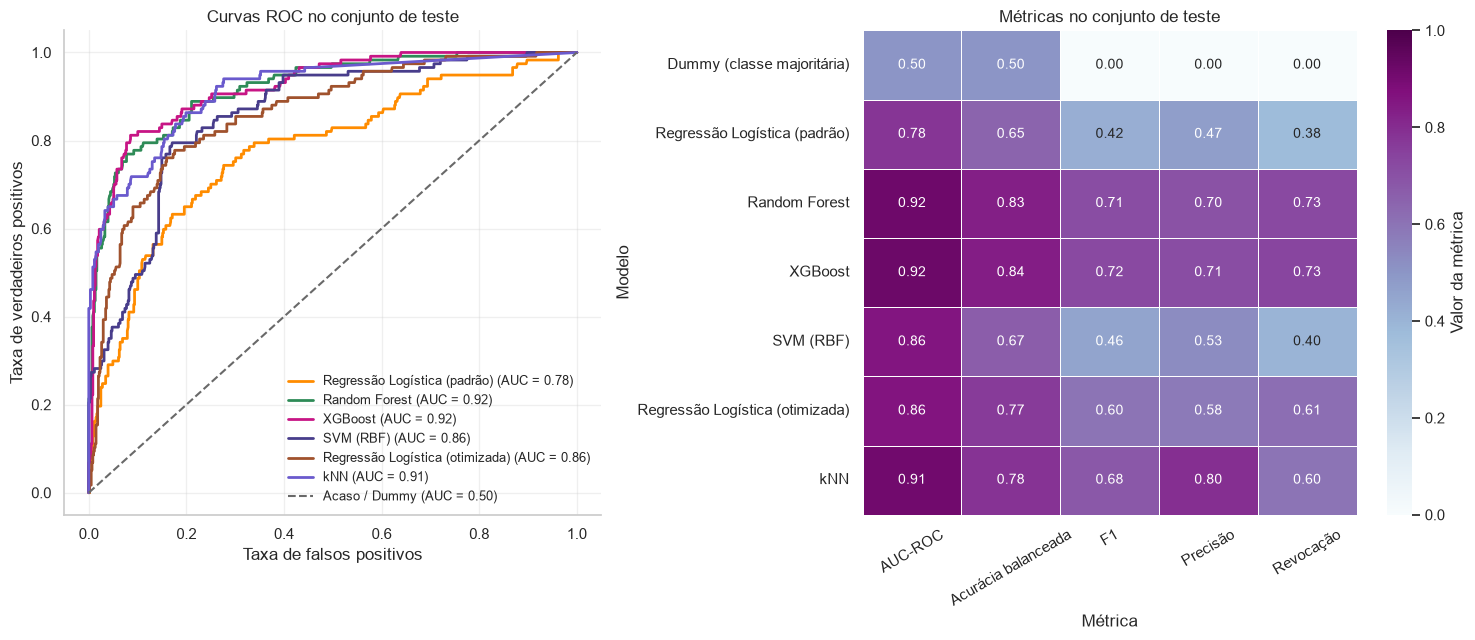

In [22]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.15]})

ax = axes[0]
for name, s in scores_test.items():
    if name.startswith("Dummy"):
        continue                      # o Dummy coincide com a diagonal tracejada
    fpr, tpr, _ = roc_curve(y_test, s)
    ax.plot(fpr, tpr, color=CORES_MODELOS[name], linewidth=2,
            label=f"{name} (AUC = {results.loc[name, 'AUC-ROC']:.2f})")
ax.plot([0, 1], [0, 1], linestyle="--", color=COR_NEUTRA, label="Acaso / Dummy (AUC = 0.50)")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos")
ax.set_title("Curvas ROC no conjunto de teste")
ax.grid(alpha=0.3)
ax.legend(loc="lower right", frameon=False, fontsize=9)

ax = axes[1]
sns.heatmap(results, annot=True, fmt=".2f", cmap=CMAP_METRICAS, vmin=0, vmax=1,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Valor da métrica"}, ax=ax)
ax.set_xlabel("Métrica")
ax.set_ylabel("Modelo")
ax.set_title("Métricas no conjunto de teste")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Interpretação:** No conjunto de teste, **os dois ensembles de árvores** (combinações de muitas árvores de decisão) **são claramente superiores**. XGBoost (AUC-ROC 0,922; acurácia balanceada 0,839; F1 0,723) e Random Forest (0,919; 0,833; 0,711) **praticamente empatam**: a diferença de 0,003 em AUC é desprezível diante da variação entre dobras, então **não é possível afirmar que um vence o outro**. Ambos superam muito o baseline (regressão logística: AUC 0,779; F1 0,419) e o SVM (AUC 0,859; F1 0,456). O SVM tem AUC razoável, mas revocação de apenas 0,40: ordena relativamente bem os experimentos, mas, com o limiar padrão, deixa passar a maioria dos tóxicos. Ou seja, **o problema do SVM está mais no limiar de decisão do que na capacidade de separar as classes** (ajustar o limiar poderia melhorar F1 e revocação).

**Não há sinal de overfitting**, visto que a AUC de teste (≈ 0,92) é até maior que a da validação cruzada (≈ 0,85). Isso não significa que o modelo seja melhor que o esperado, uma vez que o teste tem só ~20% dos materiais (e menos tóxicos, 16% contra 24% no treino), enquanto a validação cruzada contém dobras difíceis, em que Random Forest, XGBoost e SVM caem para ≈ 0,65 (pontos isolados no boxplot). A estimativa mais conservadora para materiais novos é a da validação cruzada (≈ 0,85); a do teste (≈ 0,92) é mais favorável e ruidosa.

A matriz de confusão do melhor modelo mostra **que tipo de erro** ele comete. **Em toxicologia, um falso negativo (classificar como seguro algo tóxico) costuma ser mais grave que um falso positivo**.

Melhor modelo otimizado no teste: XGBoost


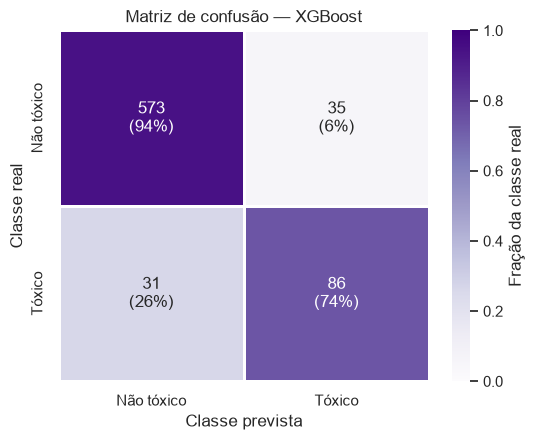

In [23]:
from sklearn.metrics import confusion_matrix

best_name = results.loc[list(best)]["AUC-ROC"].idxmax()  # melhor entre os modelos otimizados
print("Melhor modelo otimizado no teste:", best_name)

cm = confusion_matrix(y_test, models[best_name].predict(X_test))
cm_frac = cm / cm.sum(axis=1, keepdims=True)              # fração de cada classe real
rotulos = np.array([[f"{cm[i, j]}\n({cm_frac[i, j]:.0%})" for j in range(2)] for i in range(2)])
nomes = ["Não tóxico", "Tóxico"]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm_frac, annot=rotulos, fmt="", cmap=CMAP_CONFUSAO, vmin=0, vmax=1,
            annot_kws={"size": 12}, linewidths=1, linecolor="white",
            xticklabels=nomes, yticklabels=nomes,
            cbar_kws={"label": "Fração da classe real"}, ax=ax)
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.set_title(f"Matriz de confusão — {best_name}")
plt.tight_layout()
plt.show()

**Interpretação:** o XGBoost acertou 573 dos 608 experimentos não tóxicos (94%) e 86 dos 117 tóxicos (74%). **Os erros são parecidos em número (35 falsos positivos e 31 falsos negativos), mas não em gravidade**: os 31 falsos negativos (tóxicos classificados como seguros, cerca de 26% dos tóxicos) são o erro mais perigoso em toxicologia, enquanto os 35 falsos positivos (6% dos não tóxicos) apenas levariam a testes de laboratório desnecessários. **Se o objetivo for triagem de segurança, vale reduzir o limiar de decisão para aumentar a revocação, aceitando mais falsos positivos**.

### **9.1 Quanto o vazamento inflaria o desempenho? Divisão aleatória × divisão por grupos**

Todo o trabalho usa divisão **por grupos de material**. Para medir o que isso muda, **repetimos a avaliação com uma divisão aleatória por linhas**, que é o procedimento comum (e errado, neste caso): linhas "irmãs" do mesmo material (mesmas propriedades, doses e tempos diferentes) caem no treino e no teste, e **o modelo pode acertar apenas por reconhecer o material, não por ter aprendido a relação com a toxicidade**.

Mantemos **os mesmos hiperparâmetros** de cada modelo (escolhidos com a divisão por grupos) e comparamos duas avaliações:

1. **Validação cruzada** de 5 dobras no treino: `StratifiedKFold` (linhas) × `StratifiedGroupKFold` (materiais).
2. **Teste**: uma divisão aleatória 80/20 por linhas × a divisão por grupos da seção 5.

Se a divisão aleatória der AUC-ROC maior, **a diferença é o vazamento que a divisão por grupos evitou**. Como os hiperparâmetros não foram reotimizados sob a divisão aleatória, a inflação real em um fluxo completo (com busca de hiperparâmetros) tenderia a ser ainda maior.

In [24]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, train_test_split

G = "Por grupos (materiais inteiros)"
A = "Aleatória (por linhas)"
modelos_comp = {n: p for n, p in models.items() if not n.startswith("Dummy")}

# (1) validação cruzada no treino: por grupos × aleatória
cv_aleatoria = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tab_cv = pd.DataFrame({
    G: {n: cv_scores[n].mean() for n in modelos_comp},
    A: {n: cross_val_score(p, X_train, y_train, cv=cv_aleatoria, scoring="roc_auc", n_jobs=-1).mean()
        for n, p in modelos_comp.items()}})

# (2) teste: divisão aleatória por linhas × divisão por grupos (seção 5)
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, stratify=y, random_state=SEED)
frac_vazada = groups.iloc[idx_te].isin(set(groups.iloc[idx_tr])).mean()
print(f"Na divisão aleatória, {frac_vazada:.0%} das linhas de teste pertencem a materiais que também estão no treino.")

auc_aleat = {}
for n, p in modelos_comp.items():
    m = clone(p).fit(X.iloc[idx_tr], y.iloc[idx_tr])
    auc_aleat[n] = roc_auc_score(y.iloc[idx_te], score_of(m, X.iloc[idx_te]))
tab_teste = pd.DataFrame({G: results["AUC-ROC"].loc[list(modelos_comp)], A: pd.Series(auc_aleat)})

for titulo, tab in [("Validação cruzada (treino)", tab_cv), ("Teste", tab_teste)]:
    tab["Inflação (aleatória − grupos)"] = tab[A] - tab[G]
    print(f"\n{titulo}: inflação média da AUC-ROC = {tab['Inflação (aleatória − grupos)'].mean():+.3f}")
    print(tab.round(3).to_string())

Na divisão aleatória, 100% das linhas de teste pertencem a materiais que também estão no treino.

Validação cruzada (treino): inflação média da AUC-ROC = +0.104
                                 Por grupos (materiais inteiros)  Aleatória (por linhas)  Inflação (aleatória − grupos)
Regressão Logística (padrão)                               0.713                   0.838                          0.125
Random Forest                                              0.848                   0.966                          0.118
XGBoost                                                    0.853                   0.972                          0.119
SVM (RBF)                                                  0.839                   0.940                          0.101
Regressão Logística (otimizada)                            0.841                   0.923                          0.083
kNN                                                        0.844                   0.920                          0.076

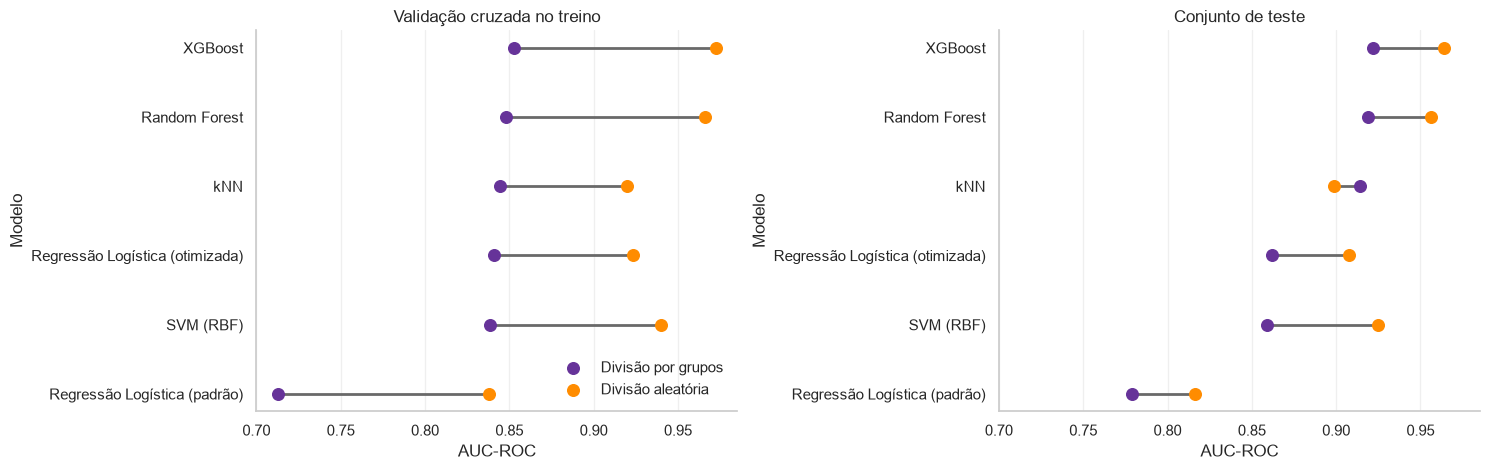

In [25]:
def halteres(ax, tab, titulo):
    ordem = tab[G].sort_values().index
    y_pos = np.arange(len(ordem))
    ax.hlines(y_pos, tab.loc[ordem, G], tab.loc[ordem, A], color=COR_NEUTRA, linewidth=2)
    ax.scatter(tab.loc[ordem, G], y_pos, color=COR_GRUPO, s=70, zorder=3, label="Divisão por grupos")
    ax.scatter(tab.loc[ordem, A], y_pos, color=COR_ALEATORIO, s=70, zorder=3, label="Divisão aleatória")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(ordem)
    ax.set_xlabel("AUC-ROC")
    ax.set_ylabel("Modelo")
    ax.set_title(titulo)
    ax.grid(axis="x", alpha=0.3)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharex=True)
halteres(axes[0], tab_cv, "Validação cruzada no treino")
halteres(axes[1], tab_teste, "Conjunto de teste")
axes[0].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Interpretação:** a divisão aleatória confirma o vazamento: em 100% das linhas do teste aleatório, o material já aparecia no treino. Em validação cruzada, a AUC-ROC média foi inflada em **+0,104**: com dobras aleatórias, Random Forest e XGBoost chegariam a 0,966 e 0,972, quando a estimativa honesta por grupos é 0,848 e 0,853. Quem usasse o procedimento padrão reportaria um modelo quase perfeito (AUC ≈ 0,97) que, para materiais novos, rende ≈ 0,85. No teste, a inflação média foi menor (**+0,035**), em parte porque o teste por grupos já tinha AUC alta (0,92), com menos espaço para subir. A estimativa aleatória é estável entre CV e teste (≈ 0,96 a 0,97 para as árvores), enquanto a por grupos varia mais (0,85 em CV e 0,92 no teste), o que reflete a dificuldade real de generalizar para materiais novos.

Quanto aos modelos, a expectativa de que os que mais memorizam inflariam mais não se confirmou: em CV, a maior inflação foi da regressão logística padrão (+0,125), seguida de XGBoost (+0,119) e Random Forest (+0,118), e a menor foi do kNN (+0,076) e da regressão logística otimizada (+0,083); no teste, a maior foi do SVM (+0,066) e a menor do Random Forest (+0,037). Como a ordem muda entre CV e teste, **a conclusão segura é que todos os modelos são inflados em CV** (de +0,076 a +0,125) e nenhum escapa do vazamento. A divisão por grupos, com AUC mais baixa, é a estimativa honesta para prever a toxicidade de **materiais novos**.

## **10. Explicando o melhor modelo: *permutation importance***

A **importância por permutação** mede quanto o desempenho cai quando os valores de **um atributo** são embaralhados no conjunto de teste, quebrando sua relação com o alvo. Se a AUC cai muito, o modelo dependia daquele atributo; se não muda, ele era irrelevante (ou redundante com outro). Como aplicamos a técnica ao pipeline completo, ela opera nos atributos **originais** (antes do *one-hot*), o que facilita a interpretação química.

*Cuidados:* atributos correlacionados dividem a importância entre si (embaralhar um deixa o outro compensar), e a medida descreve o que o **modelo** usa, não necessariamente causalidade física.

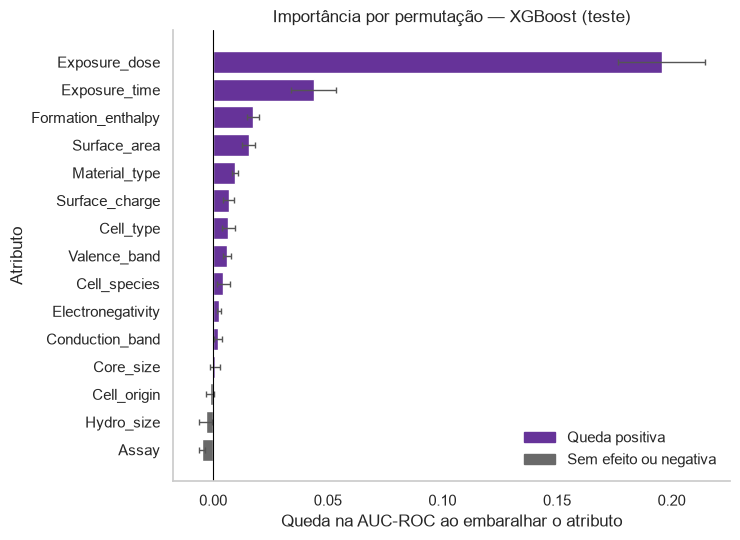

In [26]:
from matplotlib.patches import Patch

perm = permutation_importance(models[best_name], X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                   index=X_test.columns).sort_values("mean")
cores = [COR_PRIMARIA if m > 0 else COR_NEUTRA for m in imp["mean"]]

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color=cores,
        error_kw={"ecolor": "#555555", "elinewidth": 1, "capsize": 2})
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Queda na AUC-ROC ao embaralhar o atributo")
ax.set_ylabel("Atributo")
ax.set_title(f"Importância por permutação — {best_name} (teste)")
ax.legend(handles=[Patch(color=COR_PRIMARIA, label="Queda positiva"),
                   Patch(color=COR_NEUTRA, label="Sem efeito ou negativa")],
          frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Interpretação:** A **dose de exposição** domina com larga vantagem: embaralhá-la derruba a AUC-ROC em cerca de 0,20, contra cerca de 0,04 do segundo colocado, o **tempo de exposição**. Depois vêm `Formation_enthalpy` e `Surface_area` (≈ 0,015 a 0,02) e, com efeitos pequenos, `Material_type`, `Surface_charge`, `Cell_type` e `Valence_band`. Alguns atributos ficam próximos de zero ou levemente negativos dentro da barra de erro (`Core_size`, `Hydro_size`, `Cell_origin`, `Assay`): o modelo praticamente não os usa. Isso concorda com o princípio central da toxicologia, de que "a dose faz o veneno": nas condições do ensaio, quanto e por quanto tempo as células são expostas pesa mais que as propriedades do material.

**Três pontos de atenção:** (i) Atributos correlacionados dividem a importância (Seção 3): o efeito eletrônico do material aparece diluído entre `Valence_band`, `Conduction_band` e `Electronegativity`, e `Formation_enthalpy` pode estar funcionando como "identidade" do material; (ii) **Importância baixa não prova irrelevância biológica, só que o modelo não precisou do atributo**; (iii) **Os experimentos com dose 0**, que parecem ser controles e aparecem como não tóxicos no início do conjunto, são fáceis de classificar e **podem inflar a importância da dose**; portanto,  **checar o desempenho sem esses controles seria um bom teste de robustez**.

## **11. Conclusões e principais aprendizados**

- **Resultado principal:** XGBoost e Random Forest foram os melhores, com AUC-ROC no teste de 0,922 e 0,919 (empate prático) e acurácia balanceada de 0,84 e 0,83. O baseline de regressão logística ficou em 0,779 (acurácia balanceada 0,65) e o Dummy em 0,500, então os ensembles de árvores superam o baseline em cerca de 0,14 de AUC. O SVM (0,859) ficou no meio do caminho. Em validação cruzada agrupada, Random Forest, XGBoost e SVM ficaram em ≈ 0,84 a 0,85. A regressão logística otimizada (0,841) e o kNN (0,844) ficaram no mesmo patamar em CV. No teste, o kNN teve AUC de 0,91, praticamente igual à dos ensembles de árvores (0,92), e a regressão logística otimizada teve 0,86, ≈ 0,08 acima do baseline (0,78).
- **Efeito da divisão por grupos:** quantificado na seção 9.1. Com a divisão aleatória, a AUC-ROC média foi inflada em +0,104 na validação cruzada e +0,035 no teste. Random Forest e XGBoost chegariam a ≈ 0,97 em CV, contra ≈ 0,85 por grupos, e em 100% das linhas do teste aleatório o material já estava no treino. Um procedimento padrão superestimaria, portanto, a capacidade de prever a toxicidade de materiais novos. As dobras difíceis da validação por grupos (AUC ≈ 0,65 para os modelos de árvores e ≈ 0,49 para a regressão logística) reforçam que generalizar para materiais novos é bem mais difícil do que interpolar entre linhas do mesmo material.
- **O que o modelo usa:** sobretudo a dose e o tempo de exposição (queda de ≈ 0,20 e ≈ 0,04 na AUC ao embaralhá-los), seguidos de entalpia de formação e área de superfície. Propriedades do material como tamanho e bandas de energia pesam pouco, o que condiz com a ideia de que "a dose faz o veneno".
- **Limitações:** dados compilados de vários artigos (protocolos heterogêneos), apenas 232 materiais distintos (o teste tem cerca de 46), classes desbalanceadas (≈ 22% tóxicos), possíveis controles com dose zero que inflam o desempenho, valores atípicos próximos de zero nas propriedades eletrônicas e apenas óxidos metálicos, o que limita a generalização para outros nanomateriais.
- **Aprendizados metodológicos:** evitar vazamento exige pré-processamento dentro do `Pipeline` e divisão por grupos; o baseline mostrou o piso de comparação; a AUC-ROC foi mais informativa que a acurácia com classes desbalanceadas; e a mesma AUC pode esconder revocação baixa (caso do SVM), então vale olhar mais de uma métrica e o limiar de decisão.
- **Próximos passos:** ajustar o limiar de decisão para priorizar a revocação, repetir a análise sem os controles de dose zero, aplicar transformação logarítmica a atributos assimétricos, usar validação cruzada aninhada, testar outros algoritmos (como o Gradient Boosting do scikit-learn) e ferramentas como SHAP.

## **12. Descrição do uso de IA neste trabalho**

Usei o Claude (Anthropic) como suporte para: (i) buscar e comparar conjuntos de dados de saúde, neurociência e nanomateriais que atendessem aos critérios do projeto, o que levou à escolha do HaHa-Manual; (ii) planejar as etapas do pipeline (EDA, divisão por grupos para evitar vazamento, baseline, cinco algoritmos com Optuna, comparação e explicação do modelo), (iii) elaboração dos gráficos e auxílio na interpretação dos resultados obtidos, (iv) formatação do notebook (organização do material e adequação dos textos para guiar melhor o leitor);

Usei o Google Gemini (Meta) para gerar o banner inicial do README no reposiório da entrega.

## **13. Referências**

- Ha, E.; Ha, S. *Structured Nanotoxicity Datasets with Physicochemical and Toxicological Attributes of Metal Oxide Nanoparticles* (HaHa-Manual). Zenodo, 2025. https://zenodo.org/records/15385143 (licença CC-BY-4.0).
- Akiba, T. et al. Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD*, 2019.
- Chen, T.; Guestrin, C. XGBoost: A Scalable Tree Boosting System. *KDD*, 2016.
- Pedregosa, F. et al. Scikit-learn: Machine Learning in Python. *JMLR* 12, 2825–2830, 2011.
- FACELI, K. et al. Inteligência artificial: uma abordagem de aprendizado de máquina. Rio de Janeiro: LTC, 2011.
- WASKOM, M. seaborn: statistical data visualization. *Journal of Open Source Software*, v. 6, n. 60, p. 3021,
  2021. Documentação: https://seaborn.pydata.org/

---